# Prediksi Biaya Medis Menggunakan Deep Neural Network dengan Perbandingan Model Baseline
Proyek UTS Deep Learning — DNN regresi vs. baseline (Linear Regression & Random Forest).

**Alur:** 1) Load data → 2) EDA → 3) Preprocessing → 4) Baseline → 5) DNN → 6) Eksperimen arsitektur → 7) Evaluasi akhir → 8) Simpan model

## 1. Import & Konfigurasi

In [1]:
import os, random, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid"); tf.get_logger().setLevel("ERROR")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load Dataset

In [2]:
for p in ["../data/medical_insurance.csv", "data/medical_insurance.csv", "medical_insurance.csv"]:
    if os.path.exists(p):
        DATA_PATH = p; break
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1338, 8)


,age,gender,bmi,children,discount_eligibility,region,expenses,premium
0,19,female,27.9,0,yes,southwest,16884.92,168.8492
1,18,male,33.8,1,no,southeast,1725.55,17.2555
2,28,male,33.0,3,no,southeast,4449.46,44.4946
3,33,male,22.7,0,no,northwest,21984.47,439.6894
4,32,male,28.9,0,no,northwest,3866.86,77.3372


In [3]:
df.info()
print("\nMissing value:", df.isna().sum().sum())
print("Duplikat      :", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1338 non-null   int64  
 1   gender                1338 non-null   object 
 2   bmi                   1338 non-null   float64
 3   children              1338 non-null   int64  
 4   discount_eligibility  1338 non-null   object 
 5   region                1338 non-null   object 
 6   expenses              1338 non-null   float64
 7   premium               1338 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 83.8+ KB

Missing value: 0
Duplikat      : 1


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.0000,51.0000,64.0000
bmi,1338.0,30.665471,6.098382,16.0000,26.30000,30.4000,34.7000,53.1000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.0000,2.0000,5.0000
expenses,1338.0,13270.422414,12110.011240,1121.8700,4740.28750,9382.0300,16639.9150,63770.4300
premium,1338.0,262.874685,292.532178,11.2187,87.35425,174.9974,342.9089,1983.1064


## 3. Exploratory Data Analysis (EDA)
**Catatan penting — data leakage:** kolom `premium` selalu bernilai 1%, 2%, atau 4% dari `expenses`, sehingga **tidak boleh dipakai sebagai fitur**. Kita buktikan di bawah.

In [4]:
ratio = (df["premium"] / df["expenses"]).round(4)
print(ratio.value_counts())
print("Korelasi expenses-premium:", round(df["expenses"].corr(df["premium"]), 3))

0.02    803
0.01    444
0.04     91
Name: count, dtype: int64
Korelasi expenses-premium: 0.854


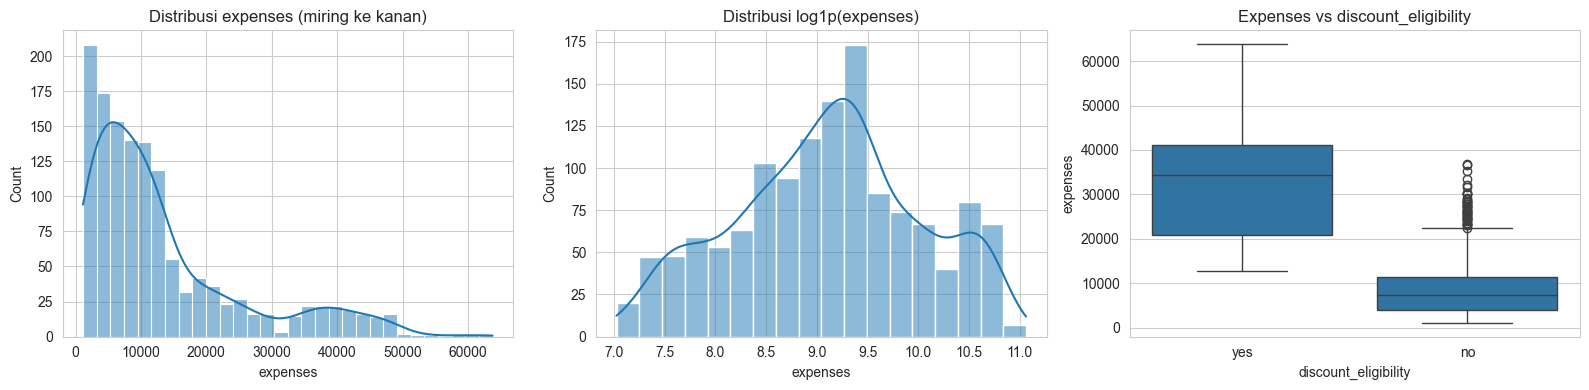

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["expenses"], kde=True, ax=ax[0]); ax[0].set_title("Distribusi expenses (miring ke kanan)")
sns.histplot(np.log1p(df["expenses"]), kde=True, ax=ax[1]); ax[1].set_title("Distribusi log1p(expenses)")
sns.boxplot(data=df, x="discount_eligibility", y="expenses", ax=ax[2]); ax[2].set_title("Expenses vs discount_eligibility")
plt.tight_layout(); plt.show()

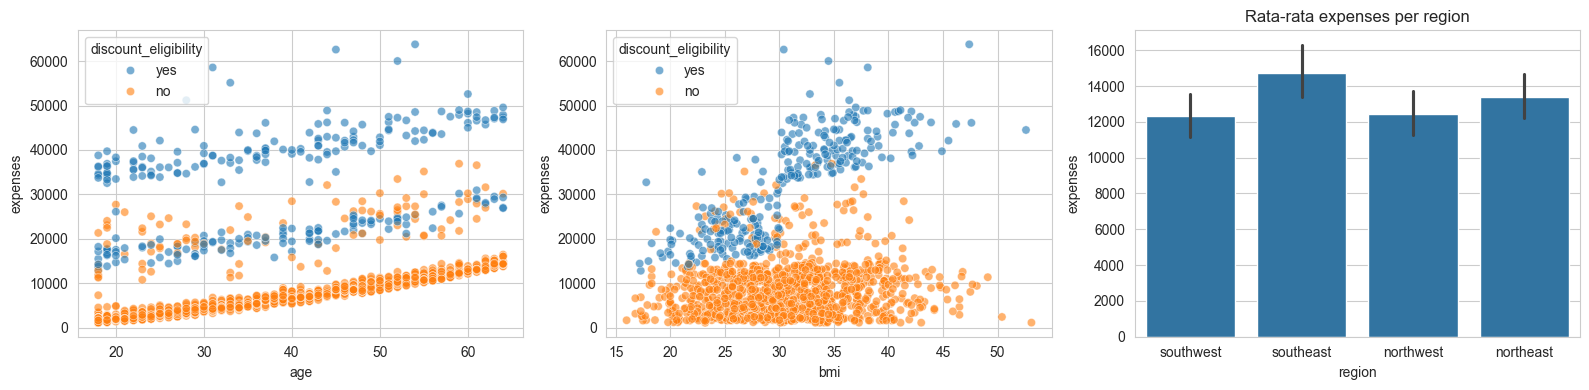

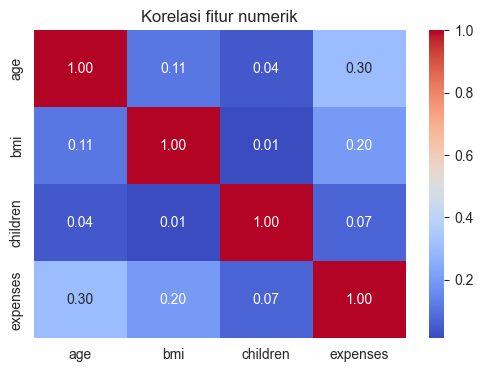

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="age", y="expenses", hue="discount_eligibility", alpha=.6, ax=ax[0])
sns.scatterplot(data=df, x="bmi", y="expenses", hue="discount_eligibility", alpha=.6, ax=ax[1])
sns.barplot(data=df, x="region", y="expenses", ax=ax[2]); ax[2].set_title("Rata-rata expenses per region")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df[["age","bmi","children","expenses"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi fitur numerik"); plt.show()

## 4. Preprocessing
1. Hapus duplikat dan kolom `premium` (leakage)
2. One-hot encoding fitur kategorikal
3. Target di-transformasi `log1p` (distribusi miring), prediksi dikembalikan dengan `expm1`
4. Split **70% train / 15% validation / 15% test**
5. `StandardScaler` hanya di-fit pada data train (mencegah leakage)

In [7]:
data = df.drop_duplicates().drop(columns=["premium"]).reset_index(drop=True)
data = pd.get_dummies(data, columns=["gender", "discount_eligibility", "region"], drop_first=True, dtype=int)

X = data.drop(columns=["expenses"])
y = data["expenses"]

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)

num_cols = ["age", "bmi", "children"]
scaler = StandardScaler().fit(X_tr[num_cols])
def prep(Xd):
    Xd = Xd.copy(); Xd[num_cols] = scaler.transform(Xd[num_cols]); return Xd
X_tr_s, X_val_s, X_te_s = prep(X_tr), prep(X_val), prep(X_te)

y_tr_log, y_val_log = np.log1p(y_tr), np.log1p(y_val)
print("Train/Val/Test:", X_tr.shape, X_val.shape, X_te.shape)
print("Fitur:", list(X.columns))

Train/Val/Test: (935, 8) (201, 8) (201, 8)
Fitur: ['age', 'bmi', 'children', 'gender_male', 'discount_eligibility_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## 5. Fungsi Evaluasi & Model Baseline
Metrik dihitung pada **skala asli** (bukan log).

In [8]:
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

results = {}

lr = LinearRegression().fit(X_tr_s, y_tr_log)
results["Linear Regression"] = evaluate(y_te, np.expm1(lr.predict(X_te_s)))

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X_tr_s, y_tr_log)
results["Random Forest"] = evaluate(y_te, np.expm1(rf.predict(X_te_s)))

pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
Linear Regression,3570.213,7230.611,0.694
Random Forest,2082.563,4583.214,0.877


## 6. Model DNN
**Justifikasi desain:**
- Data tabular dengan 8 fitur setelah encoding → DNN (MLP) cukup; CNN tidak relevan karena tidak ada struktur spasial.
- **ReLU** pada hidden layer (cepat, mengurangi vanishing gradient); **output linear** karena regresi.
- **Adam** (learning rate adaptif), **loss MSE** pada target log, **EarlyStopping** + **Dropout** untuk mengurangi overfitting pada dataset yang kecil (~1.3 ribu baris).

In [9]:
def build_dnn(units=(64, 32, 16), dropout=0.1, lr=1e-3, optimizer="adam", activation="relu"):
    tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
    m = keras.Sequential([layers.Input(shape=(X_tr_s.shape[1],))])
    for u in units:
        m.add(layers.Dense(u, activation=activation))
        if dropout > 0: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1))
    opt = {"adam": keras.optimizers.Adam, "sgd": keras.optimizers.SGD, "rmsprop": keras.optimizers.RMSprop}[optimizer](learning_rate=lr)
    m.compile(optimizer=opt, loss="mse", metrics=["mae"])
    return m

def train(model, epochs=800):
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
    return model.fit(X_tr_s, y_tr_log, validation_data=(X_val_s, y_val_log),
                     epochs=epochs, batch_size=32, callbacks=[es], verbose=0)

dnn = build_dnn()
dnn.summary()
history = train(dnn)
print("Epoch berhenti di:", len(history.history["loss"]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch berhenti di: 94


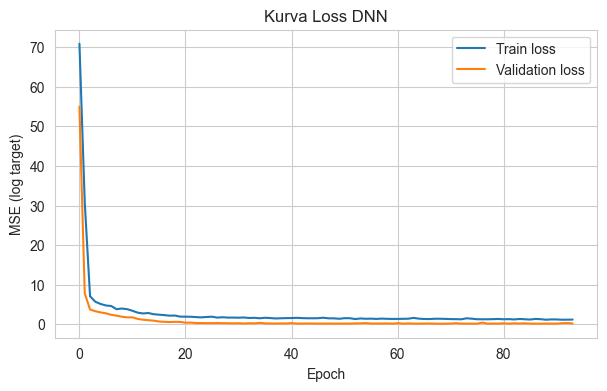

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE (log target)"); plt.title("Kurva Loss DNN"); plt.legend(); plt.show()

## 7. Eksperimen Arsitektur (bukti justifikasi)
Beberapa konfigurasi dibandingkan pada **validation set** (test set tidak disentuh).

In [11]:
configs = {
    "Shallow (16)":              dict(units=(16,), dropout=0.0),
    "2 layer (32-16)":           dict(units=(32, 16), dropout=0.0),
    "3 layer (64-32-16)":        dict(units=(64, 32, 16), dropout=0.0),
    "3 layer + Dropout 0.1":     dict(units=(64, 32, 16), dropout=0.1),
    "Deep (128-64-32-16) + D0.2":dict(units=(128, 64, 32, 16), dropout=0.2),
    "3 layer + Dropout, SGD":    dict(units=(64, 32, 16), dropout=0.1, optimizer="sgd", lr=1e-2),
    "3 layer + Dropout, RMSprop":dict(units=(64, 32, 16), dropout=0.1, optimizer="rmsprop"),
    "3 layer + Dropout, tanh":   dict(units=(64, 32, 16), dropout=0.1, activation="tanh"),
}
rows = []
for name, cfg in configs.items():
    m = build_dnn(**cfg); h = train(m)
    pred = np.expm1(m.predict(X_val_s, verbose=0).ravel())
    r = evaluate(y_val, pred); r["Epoch"] = len(h.history["loss"]); r["Konfigurasi"] = name
    rows.append(r)
exp_df = pd.DataFrame(rows).set_index("Konfigurasi").sort_values("RMSE")
exp_df.round(3)

,MAE,RMSE,R2,Epoch
Konfigurasi,,,,
Shallow (16),2989.057,5183.080,0.843,371
"3 layer + Dropout, SGD",2800.050,5244.905,0.839,61
3 layer + Dropout 0.1,3003.861,5519.690,0.822,183
2 layer (32-16),3233.663,5595.109,0.817,211
Deep (128-64-32-16) + D0.2,3035.360,5804.232,0.803,98
"3 layer + Dropout, RMSprop",3355.071,5853.420,0.800,118
3 layer (64-32-16),3579.636,7405.933,0.679,134
"3 layer + Dropout, tanh",4499.881,7454.930,0.675,215


## 8. Evaluasi Akhir pada Test Set

In [12]:
best_name = exp_df.index[0]
print("Konfigurasi terbaik (validation RMSE):", best_name)
best_cfg = configs[best_name]
final = build_dnn(**best_cfg); hist_final = train(final)
pred_te = np.expm1(final.predict(X_te_s, verbose=0).ravel())
results["DNN (terbaik)"] = evaluate(y_te, pred_te)

final_df = pd.DataFrame(results).T.round(3)
final_df

Konfigurasi terbaik (validation RMSE): Shallow (16)


,MAE,RMSE,R2
Linear Regression,3570.213,7230.611,0.694
Random Forest,2082.563,4583.214,0.877
DNN (terbaik),3086.642,5938.255,0.793


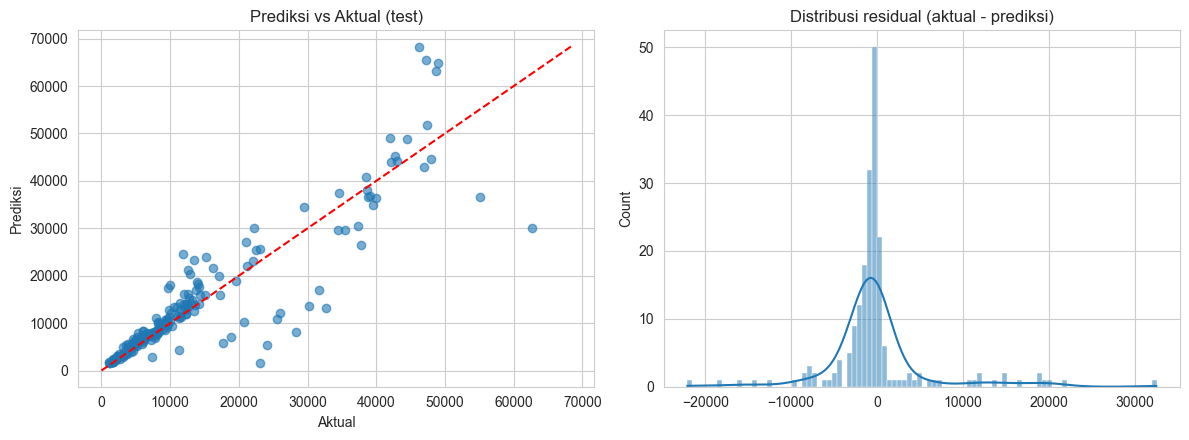

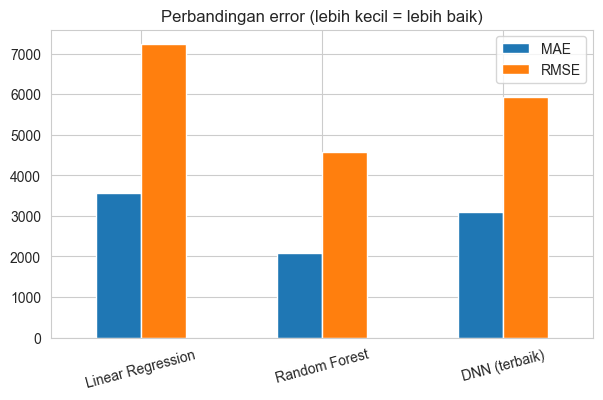

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_te, pred_te, alpha=.6)
lim = [0, max(y_te.max(), pred_te.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Aktual"); ax[0].set_ylabel("Prediksi"); ax[0].set_title("Prediksi vs Aktual (test)")
sns.histplot(y_te.values - pred_te, kde=True, ax=ax[1]); ax[1].set_title("Distribusi residual (aktual - prediksi)")
plt.tight_layout(); plt.show()

final_df[["MAE", "RMSE"]].plot(kind="bar", figsize=(7, 4), title="Perbandingan error (lebih kecil = lebih baik)")
plt.xticks(rotation=15); plt.show()

## 9. Simpan Model & Preprocessing (untuk deployment)

In [14]:
os.makedirs("../models", exist_ok=True)
final.save("../models/dnn_medical_cost.keras")
joblib.dump({"scaler": scaler, "num_cols": num_cols, "columns": list(X.columns)}, "../models/preprocessor.joblib")
print("Tersimpan di ../models/")

Tersimpan di ../models/


## 10. Kesimpulan (isi setelah menjalankan notebook)
- Bandingkan MAE, RMSE, R² antara DNN dan baseline pada tabel di bagian 8.
- Jelaskan fitur paling berpengaruh (`discount_eligibility`, `age`, `bmi`) dan mengapa `premium` dibuang.
- Jelaskan keterbatasan: dataset kecil (~1.3 ribu baris), error pada biaya sangat tinggi.
- Jika Random Forest mengungguli DNN, laporkan apa adanya dan analisis penyebabnya (dataset tabular kecil); jangan ubah hasil.